## v2.2 Boundary trial with adaptive time step: Meso (full Mercator UVW), continuous time

Same experiment as `v2.Meso_boundaries_trial` (same seed, particles, dates), but advected with **RK4 + adaptive dt at solid boundaries**:

* each particle step of `dt = time_step_minutes` is integrated with RK4-3D sub-steps inside the kernel;
* if any RK4 stage position or the end point of a sub-step lies in a cell where u = v = w = 0 (ground: land or below the W bottom),
  that sub-step is **not taken**: it is halved and recomputed (down to `dt_min_seconds`);
* after an accepted sub-step it doubles again, up to the remaining part of `dt`.

Nothing is deleted, nudged or reflected: steps near a corner of the stepped bathymetry are just integrated with a smaller dt
(the sub-stepping loop is inside the kernel, so `particle.dt` and the output times stay fixed; no `StatusCode.Repeat`).

Groups: **coast** (wet cells touching land, 0-7 m), **shelf_bottom** (W bottom 20-100 m, one W level above the W bottom), **ocean_bottom** (W bottom > 3000 m, one W level above the W bottom).

Checks: deleted, frozen (identical lon/lat for many outputs), above the surface, below the W bottom (cell parcels uses), on land, clashing, and how often dt was refined. Comparison with the plain RK4 run of v2.

In [1]:
n_per_group = 1000
run_time_days = 100
time_step_minutes = 20     # maximum dt
dt_min_seconds = 1         # smallest dt the refinement may reach
frozen_min_obs = 8         # identical lon/lat for >= this many consecutive outputs -> frozen (8 x 6 h = 2 days)
baseline_path = 'tracks_boundaries_16/'   # plain RK4 run (v2) with the same seed, for comparison
out_put_step_hours = 6

depth_min = 0      # coast group depth range
depth_max = 7

offset = 550
ref_date = "1993-01-01"
#reproducibility
rdm_seed = 16
#paths
pathUVW= '/work/bk1450/b383184/Amazon/Mercator/data/variables_c/UVW'
Hgr = "/work/bk1450/b383184/Amazon/Mercator/data/Hgr_cmesh.nc"
Zgr = "/work/bk1450/b383184/Amazon/Mercator/data/Zgr_cmesh2.nc"

# boxes (lon0, lon1, lat0, lat1) where each group is drawn
box_shelf = (-52, -44, -2, 6)     # Amazon / Para shelf
box_ocean = (-48, -40, 2, 10)     # deep ocean offshore

In [2]:
import numpy as np

In [3]:
out_path = f'tracks_boundaries_adaptive_{rdm_seed}/' #path to store the particle zarr
groups = ["coast", "shelf_bottom", "ocean_bottom"]

start_time = np.datetime64(ref_date) + np.timedelta64(offset, "D")
start_time

np.datetime64('1994-07-05')

In [4]:
import pandas as pd
start_time = pd.to_datetime(start_time)
t_plus_2y = start_time + pd.DateOffset(years=2)

st_yr = str(start_time)[0:4]
end_yr = str(t_plus_2y)[0:4]

print(st_yr)
print(end_yr)

1994
1996


## Particles from the ARP to the Atlantic

In [5]:
from parcels import ParticleSet
from parcels import JITParticle
from parcels import AdvectionRK4_3D
from parcels import Variable
from datetime import timedelta
from parcels import FieldSet
from parcels import StatusCode

In [6]:
np.random.seed(rdm_seed)

In [7]:
from pathlib import Path
import os

def files_span(base, prefix, st_yr, end_yr, suffix='c.nc'):
    # all months from Jan st_yr to Dec end_yr
    months = pd.period_range(f'{st_yr}-01', f'{end_yr}-12', freq='M')
    pats = [Path(base) / f"{prefix}_{p.year}-{p.month:02d}{suffix}" for p in months]
    # keep only existing files
    return [str(p) for p in pats if p.exists()]

ufiles = files_span(pathUVW, 'U', st_yr, end_yr, 'c.nc')
vfiles = files_span(pathUVW, 'V', st_yr, end_yr, 'c.nc')
wfiles = files_span(pathUVW, 'W', st_yr, end_yr, 'fc.nc') 
# tfiles = files_span(pathTS,  'T', st_yr, end_yr, 'c.nc')
# sfiles = files_span(pathTS,  'S', st_yr, end_yr, 'c.nc')

In [8]:
## define the fieldset
filenames = {
    "U": {
        "data":ufiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles[0],
    },
    
    "V": {
        "data": vfiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles[0],
    },
    
    "W": {
        "data": wfiles,
        "lon": Hgr,
        "lat": Hgr,
        "depth": wfiles[0],
    },
}

variables = {
    "U": "vozocrtx",
    "V": "vomecrty",
    "W": "vovecrtz",
}

interp_method = {
    "U":"cgrid_velocity",
    "V":"cgrid_velocity",
    "W":"cgrid_velocity",
}


dimensions = {
    "U": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
    "V": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
    "W": {"lon": "glamf", "lat": "gphif", "depth": "depthw", "time": "time_counter"},
}


## now the fieldset
fieldset = FieldSet.from_nemo(
    filenames, 
    variables, 
    dimensions,
    # interp_method = interp_method,
    # tracer_interp_method="cgrid_tracer",
    deferred_load=True,
    allow_time_extrapolation = False,
    # gridindexingtype = "nemo",
)


## Model grid: land mask, W bottom, coast cells

In [9]:
import xarray as xr

_h = xr.open_dataset(Hgr)
_z = xr.open_dataset(Zgr)
glamt = _h.glamt.isel(t=0).values          # T points = cell centres
gphit = _h.gphit.isel(t=0).values
glamf = _h.glamf.isel(t=0).values          # f points = cell corners
gphif = _h.gphif.isel(t=0).values
mbathy = _z.mbathy.isel(t=0).values.astype(int)   # wet T levels per column (0 = land)
depthw = xr.open_dataset(wfiles[0]).depthw.values
nz = len(depthw)

# W bottom of each column (the W level under the deepest wet T cell)
w_bottom = np.where(mbathy > 0, depthw[np.minimum(mbathy, nz - 1)], 0.0)

land = mbathy == 0
touches_land = np.zeros_like(land)
touches_land[1:-1, 1:-1] = land[:-2, 1:-1] | land[2:, 1:-1] | land[1:-1, :-2] | land[1:-1, 2:]

def in_box(b):
    return (glamt > b[0]) & (glamt < b[1]) & (gphit > b[2]) & (gphit < b[3])

kmin = int(np.searchsorted(depthw, depth_max))   # levels needed to hold depth_max
interior = np.zeros_like(land); interior[2:-2, 2:-2] = True   # stay off the domain edges

candidates = {
    "coast":        in_box(box_shelf) & interior & ~land & touches_land & (mbathy >= kmin),
    "shelf_bottom": in_box(box_shelf) & interior & ~land & ~touches_land & (w_bottom >= 20) & (w_bottom <= 100),
    "ocean_bottom": in_box(box_ocean) & interior & ~land & (w_bottom > 3000) & (mbathy < nz),
}
for g, m in candidates.items():
    print(f"{g:13s}: {m.sum()} candidate cells")

coast        : 215 candidate cells
shelf_bottom : 1495 candidate cells
ocean_bottom : 8687 candidate cells


## Seeding

In [10]:
start_lon, start_lat, start_depth, start_group = [], [], [], []
for gi, g in enumerate(groups):
    jj, ii = np.where(candidates[g])
    # reuse cells when a group has fewer cells than particles (coast has only a few hundred)
    pick = np.random.choice(len(jj), n_per_group, replace=n_per_group > len(jj))
    j, i = jj[pick], ii[pick]
    # random position inside the T cell, whose corners are f(j-1,i-1)..f(j,i)
    start_lon.append(np.random.uniform(glamf[j, i-1], glamf[j, i]))
    start_lat.append(np.random.uniform(gphif[j-1, i], gphif[j, i]))
    if g == "coast":
        start_depth.append(np.random.uniform(depth_min, depth_max, n_per_group))
    else:
        start_depth.append(depthw[mbathy[j, i] - 1])     # one W level above the W bottom
    start_group.append(np.full(n_per_group, gi))

start_lon = np.concatenate(start_lon)
start_lat = np.concatenate(start_lat)
start_depth = np.concatenate(start_depth)
start_group = np.concatenate(start_group)
num_particles = len(start_lon)
start_times = np.datetime64(start_time)

for gi, g in enumerate(groups):
    s = start_group == gi
    print(f"{g:13s}: depth {start_depth[s].min():8.2f} - {start_depth[s].max():8.2f} m")

coast        : depth     0.01 -     7.00 m
shelf_bottom : depth    19.99 -    71.56 m
ocean_bottom : depth  2696.58 -  5052.47 m


In [11]:
# sanity check: no seed below the W bottom, and none on land
def cell_of(lon, lat):
    """T cell (j,i) parcels uses: corners f(j-1,i-1)..f(j,i)"""
    i = np.searchsorted(glamf[250, :], lon)
    j = np.searchsorted(gphif[:, 600], lat)
    for _ in range(2):   # refine on the (nearly regular) curvilinear grid
        i = np.clip(i, 1, glamf.shape[1] - 1); j = np.clip(j, 1, glamf.shape[0] - 1)
        i = i + (lon > glamf[j, i]).astype(int) - (lon <= glamf[j, i - 1]).astype(int)
        j = j + (lat > gphif[j, i]).astype(int) - (lat <= gphif[j - 1, i]).astype(int)
    return np.clip(j, 1, glamf.shape[0] - 1), np.clip(i, 1, glamf.shape[1] - 1)

j, i = cell_of(start_lon, start_lat)
assert np.all(start_depth < w_bottom[j, i]), "some seeds are below the W bottom"
print("all seeds above the W bottom")

# Land velocities are zeroed on load, so an exactly-zero UVW means a dry cell.
fieldset.computeTimeChunk(fieldset.U.grid.time[0], 1)
_t = fieldset.U.grid.time[0]
_dry = np.array([fieldset.UVW[_t, d, la, lo] == (0.0, 0.0, 0.0)
                 for lo, la, d in zip(start_lon, start_lat, start_depth)])
print(", ".join(f"{g} {_dry[start_group == gi].sum()}/{n_per_group}" for gi, g in enumerate(groups)) + " seeded on land")
assert _dry.sum() == 0, "some particles are on land" 

all seeds above the W bottom


coast 0/1000, shelf_bottom 0/1000, ocean_bottom 0/1000 seeded on land


In [12]:
BoundaryParticle = JITParticle.add_variables([
    Variable("group", dtype=np.int32, to_write="once"),
    Variable("nrefine", dtype=np.int32, initial=0),     # sub-steps redone with half the step (cumulative)
    Variable("ndry", dtype=np.int32, initial=0),        # sub-steps accepted although still dry (should stay 0)
])

fieldset.add_constant("dt_min", float(dt_min_seconds))

pset = ParticleSet(
    fieldset=fieldset,
    pclass=BoundaryParticle,
    lon=start_lon,
    lat=start_lat,
    depth=start_depth,
    time=start_times,
    group=start_group,
)

out_fn = f'Parcels_boundaries_{rdm_seed}_{str(start_time)[:10]}.zarr'

output_file = pset.ParticleFile(
    name=out_path+out_fn,
    outputdt=timedelta(hours=out_put_step_hours),
    chunks=(num_particles, int(run_time_days*24/out_put_step_hours/4)),
)

In [13]:
##check the error: print what killed the particle, then delete it
def CheckError(particle, fieldset, time):
    if particle.state >= 50:  # This captures all Errors
        print("ERROR state=%d group=%d lon=%f lat=%f z=%f" % (particle.state, particle.group, particle.lon, particle.lat, particle.depth))
        particle.delete()

In [14]:
import math

# RK4-3D with sub-stepping at solid boundaries, done inside the kernel (no StatusCode.Repeat, particle.dt stays constant).
# A trial step whose RK4 stages or end point fall in a cell with u = v = w = 0 (ground) is not taken:
# the sub-step h is halved and recomputed (down to fieldset.dt_min); after an accepted sub-step h doubles back.
def AdvectionRK4_3D_substep(particle, fieldset, time):
    lon0 = particle.lon
    lat0 = particle.lat
    dep0 = particle.depth
    t = time
    remaining = particle.dt
    h = particle.dt
    while remaining > 1e-6:
        if h > remaining:
            h = remaining
        (u1, v1, w1) = fieldset.UVW[t, dep0, lat0, lon0, particle]
        lon1 = lon0 + u1 * 0.5 * h
        lat1 = lat0 + v1 * 0.5 * h
        dep1 = dep0 + w1 * 0.5 * h
        (u2, v2, w2) = fieldset.UVW[t + 0.5 * h, dep1, lat1, lon1, particle]
        lon2 = lon0 + u2 * 0.5 * h
        lat2 = lat0 + v2 * 0.5 * h
        dep2 = dep0 + w2 * 0.5 * h
        (u3, v3, w3) = fieldset.UVW[t + 0.5 * h, dep2, lat2, lon2, particle]
        lon3 = lon0 + u3 * h
        lat3 = lat0 + v3 * h
        dep3 = dep0 + w3 * h
        (u4, v4, w4) = fieldset.UVW[t + h, dep3, lat3, lon3, particle]
        dlon = (u1 + 2 * u2 + 2 * u3 + u4) / 6 * h
        dlat = (v1 + 2 * v2 + 2 * v3 + v4) / 6 * h
        ddep = (w1 + 2 * w2 + 2 * w3 + w4) / 6 * h
        (u5, v5, w5) = fieldset.UVW[t + h, dep0 + ddep, lat0 + dlat, lon0 + dlon, particle]
        dry = 0
        if u2 == 0 and v2 == 0 and w2 == 0:
            dry = 1
        if u3 == 0 and v3 == 0 and w3 == 0:
            dry = 1
        if u4 == 0 and v4 == 0 and w4 == 0:
            dry = 1
        if u5 == 0 and v5 == 0 and w5 == 0:
            dry = 1
        if u1 == 0 and v1 == 0 and w1 == 0:
            dry = 2   # already in a zero-velocity cell: a smaller step cannot help
        if dry == 1 and h > fieldset.dt_min:
            h = h / 2
            particle.nrefine += 1
        else:
            lon0 = lon0 + dlon
            lat0 = lat0 + dlat
            dep0 = dep0 + ddep
            t = t + h
            remaining = remaining - h
            if dry > 0:
                particle.ndry += 1
            h = h * 2
    particle_dlon += lon0 - particle.lon  # noqa
    particle_dlat += lat0 - particle.lat  # noqa
    particle_ddepth += dep0 - particle.depth  # noqa


In [15]:
## Execute particles
import time as _time
_tic = _time.time()
pset.execute(
    [AdvectionRK4_3D_substep, CheckError],
    runtime=timedelta(days=run_time_days),
    dt=timedelta(minutes=time_step_minutes),
    output_file=output_file,
)
print(f'runtime {(_time.time() - _tic)/60:.1f} min')

INFO: Output files are stored in tracks_boundaries_adaptive_16/Parcels_boundaries_16_1994-07-05.zarr.


  0%|          | 0/8640000.0 [00:00<?, ?it/s]

  0%|          | 1200.0/8640000.0 [00:13<27:33:40, 87.07it/s]

  0%|          | 21600.0/8640000.0 [00:14<1:07:51, 2116.90it/s]

  0%|          | 43200.0/8640000.0 [00:21<57:22, 2497.39it/s]  

  1%|          | 64800.0/8640000.0 [00:22<33:18, 4291.10it/s]

... (396 outputs left out)

100%|█████████▉| 8618400.0/8640000.0 [13:35<00:02, 8378.96it/s]

100%|██████████| 8640000.0/8640000.0 [13:36<00:00, 10610.32it/s]

100%|██████████| 8640000.0/8640000.0 [13:36<00:00, 10578.24it/s]


runtime 13.7 min


## Diagnostics

In [16]:
ds_traj = xr.open_zarr(out_path+out_fn).compute()
lon, lat, z = ds_traj.lon.values, ds_traj.lat.values, ds_traj.z.values
grp = ds_traj.group.values.astype(int)   # stored as float in the zarr
valid = ~np.isnan(lat)
n_obs = ds_traj.sizes["obs"]
days = np.arange(n_obs) * out_put_step_hours / 24

def haversine_km(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.deg2rad, (lon1, lat1, lon2, lat2))
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

# position -> model cell (the cell parcels uses)
jj, ii = cell_of(np.nan_to_num(lon.ravel()), np.nan_to_num(lat.ravel()))
wb = np.where(valid, w_bottom[jj, ii].reshape(lon.shape), np.nan)
on_land = (mbathy[jj, ii] == 0).reshape(lon.shape) & valid
below_bed = (z > wb) & valid
above_surf = (z < 0) & valid

# frozen: identical lon and lat for >= frozen_min_obs consecutive outputs
def frozen_runs(lon, lat):
    same = (np.diff(lon, axis=1) == 0) & (np.diff(lat, axis=1) == 0)
    run = np.zeros(lon.shape[0], int); longest = np.zeros(lon.shape[0], int)
    for t in range(same.shape[1]):
        run = np.where(same[:, t], run + 1, 0); longest = np.maximum(longest, run)
    return longest
frozen_longest = frozen_runs(lon, lat)
frozen = frozen_longest >= frozen_min_obs

# clashing: two particles within 100 m and 1 m depth at the same output
# (pairs already that close at release are ignored)
def close_pairs(t):
    d = haversine_km(lon[:, None, t], lat[:, None, t], lon[None, :, t], lat[None, :, t])
    return (d < 0.1) & (np.abs(z[:, None, t] - z[None, :, t]) < 1)

close0 = close_pairs(0)
clash = np.zeros(lon.shape[0], dtype=bool)
for t in range(1, n_obs):
    clash |= (close_pairs(t) & ~close0).any(axis=1)

flags = dict(deleted=~valid[:, -1], frozen=frozen, below_bed=below_bed.any(axis=1),
             above_surface=above_surf.any(axis=1), on_land=on_land.any(axis=1), clashing=clash)

rows = []
for gi, g in enumerate(groups):
    s = grp == gi
    row = {"group": g}
    row.update({k: int(v[s].sum()) for k, v in flags.items()})
    row["alive_at_end"] = int(valid[s, -1].sum())
    row["max_z [m]"] = round(float(np.nanmax(z[s])), 1)
    rows.append(row)
summary = pd.DataFrame(rows).set_index("group")
summary

,deleted,frozen,below_bed,above_surface,on_land,clashing,alive_at_end,max_z [m]
group,,,,,,,,
coast,0,1,0,0,0,14,1000,44.8
shelf_bottom,0,0,0,0,0,4,1000,199.9
ocean_bottom,0,0,0,0,0,0,1000,5181.1


In [17]:
# how often the time step was refined
nref = np.nan_to_num(ds_traj.nrefine.values).max(axis=1).astype(int)
ndry = np.nan_to_num(ds_traj.ndry.values).max(axis=1).astype(int)
ref = pd.DataFrame({g: {"particles refined at least once": int((nref[grp == gi] > 0).sum()),
                        "% refined": round(100 * (nref[grp == gi] > 0).mean(), 2),
                        "refined steps (total)": int(nref[grp == gi].sum()),
                        "max refined steps per particle": int(nref[grp == gi].max()),
                        "steps still dry at dt_min": int(ndry[grp == gi].sum())}
                    for gi, g in enumerate(groups)}).T
n_steps = run_time_days * 24 * 60 / time_step_minutes
print(f"refined sub-steps: {nref.sum()} over ~{n_steps * num_particles:.0f} particle steps ({100 * nref.sum() / (n_steps * num_particles):.4f} %)")
ref

refined sub-steps: 615 over ~21600000 particle steps (0.0028 %)


,particles refined at least once,% refined,refined steps (total),max refined steps per particle,steps still dry at dt_min
coast,97.0,9.7,269.0,12.0,3173.0
shelf_bottom,132.0,13.2,301.0,14.0,0.0
ocean_bottom,19.0,1.9,45.0,11.0,0.0


In [18]:
# comparison with the plain RK4 run (v2, same seed and particles)
import glob
base_file = sorted(glob.glob(baseline_path + '*.zarr'))
if base_file and xr.open_zarr(base_file[0]).sizes['trajectory'] == lon.shape[0]:
    b = xr.open_zarr(base_file[0]).compute()
    blon, blat, bz = b.lon.values, b.lat.values, b.z.values
    bvalid = ~np.isnan(blat)
    same_start = np.allclose(blon[:, 0], lon[:, 0]) and np.allclose(blat[:, 0], lat[:, 0]) and np.allclose(bz[:, 0], z[:, 0])
    print("same starting positions as the plain RK4 run:", same_start)
    bj, bi = cell_of(np.nan_to_num(blon.ravel()), np.nan_to_num(blat.ravel()))
    bbelow = ((bz > w_bottom[bj, bi].reshape(bz.shape)) & bvalid).any(axis=1)
    bfrozen = frozen_runs(blon, blat) >= frozen_min_obs
    bgrp = b.group.values.astype(int)
    comp = pd.DataFrame({
        "plain RK4 below_bed": [int(bbelow[bgrp == gi].sum()) for gi in range(3)],
        "adaptive below_bed": [int(flags["below_bed"][grp == gi].sum()) for gi in range(3)],
        "plain RK4 frozen": [int(bfrozen[bgrp == gi].sum()) for gi in range(3)],
        "adaptive frozen": [int(flags["frozen"][grp == gi].sum()) for gi in range(3)],
    }, index=groups)
    comp.loc["total"] = comp.sum()
    display(comp)
    sep = haversine_km(blon[:, -1], blat[:, -1], lon[:, -1], lat[:, -1])
    print(f"end-position difference plain vs adaptive: median {np.nanmedian(sep):.1f} km, "
          f"{(sep < 1).mean()*100:.1f} % of particles within 1 km")
else:
    print("no comparable baseline run (same particle number) in", baseline_path)

same starting positions as the plain RK4 run: True


,plain RK4 below_bed,adaptive below_bed,plain RK4 frozen,adaptive frozen
coast,1,0,1,1
shelf_bottom,5,0,5,0
ocean_bottom,3,0,3,0
total,9,0,9,1


end-position difference plain vs adaptive: median 0.0 km, 92.0 % of particles within 1 km


In [19]:
# details of every flagged particle
for k, v in flags.items():
    for p in np.where(v)[0]:
        last = np.where(valid[p])[0][-1]
        extra = ""
        if k == "frozen":
            extra = f"longest identical position {frozen_longest[p]*out_put_step_hours/24:.1f} days"
        if k == "below_bed":
            extra = f"max {np.nanmax(z[p]-wb[p]):.1f} m below W bottom at day {days[np.nanargmax(z[p]-wb[p])]:.2f}"
        print(f"{k:13s} traj {p:2d} ({groups[grp[p]]:12s}) last valid day {days[last]:6.2f} "
              f"lon {lon[p, last]:.3f} lat {lat[p, last]:.3f} z {z[p, last]:.1f}  {extra}")

frozen        traj 673 (coast       ) last valid day  99.75 lon -49.701 lat 0.875 z 12.4  longest identical position 44.0 days
clashing      traj 28 (coast       ) last valid day  99.75 lon -48.581 lat -1.360 z 8.7  
clashing      traj 49 (coast       ) last valid day  99.75 lon -55.322 lat 7.592 z 3.4  
clashing      traj 69 (coast       ) last valid day  99.75 lon -70.326 lat 12.984 z 0.6  
clashing      traj 378 (coast       ) last valid day  99.75 lon -67.255 lat 15.664 z 1.1  
clashing      traj 435 (coast       ) last valid day  99.75 lon -48.542 lat -0.993 z 5.9  
clashing      traj 509 (coast       ) last valid day  99.75 lon -58.748 lat 13.256 z 25.8  
clashing      traj 594 (coast       ) last valid day  99.75 lon -66.332 lat 15.507 z 23.6  
clashing      traj 602 (coast       ) last valid day  99.75 lon -66.098 lat 15.401 z 24.1  
clashing      traj 660 (coast       ) last valid day  99.75 lon -67.405 lat 13.403 z 0.6  
clashing      traj 667 (coast       ) last valid day  9

## Plotting

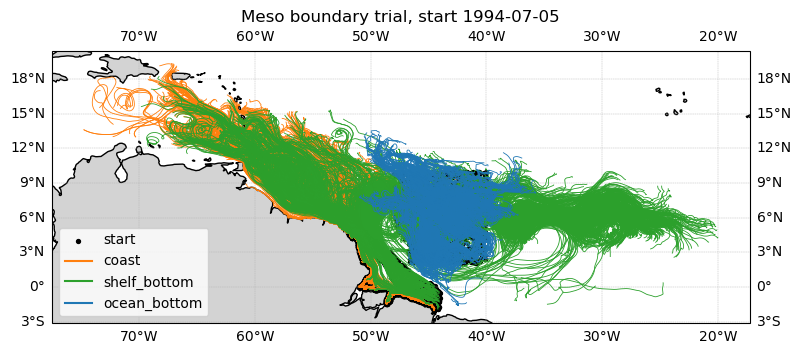

In [20]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

colors = {"coast": "tab:orange", "shelf_bottom": "tab:green", "ocean_bottom": "tab:blue"}
fig = plt.figure(figsize=(9, 7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.coastlines(resolution='50m')
ax.gridlines(draw_labels=True, linestyle='--', linewidth=0.3)
for p in range(num_particles):
    ax.plot(lon[p], lat[p], lw=0.6, color=colors[groups[grp[p]]], transform=ccrs.PlateCarree())
ax.scatter(start_lon, start_lat, s=8, color='k', transform=ccrs.PlateCarree(), label='start')
for g, c in colors.items():
    ax.plot([], [], color=c, label=g)
ax.legend(loc='lower left')
plt.title(f'Meso boundary trial, start {str(start_time)[:10]}')
plt.show()

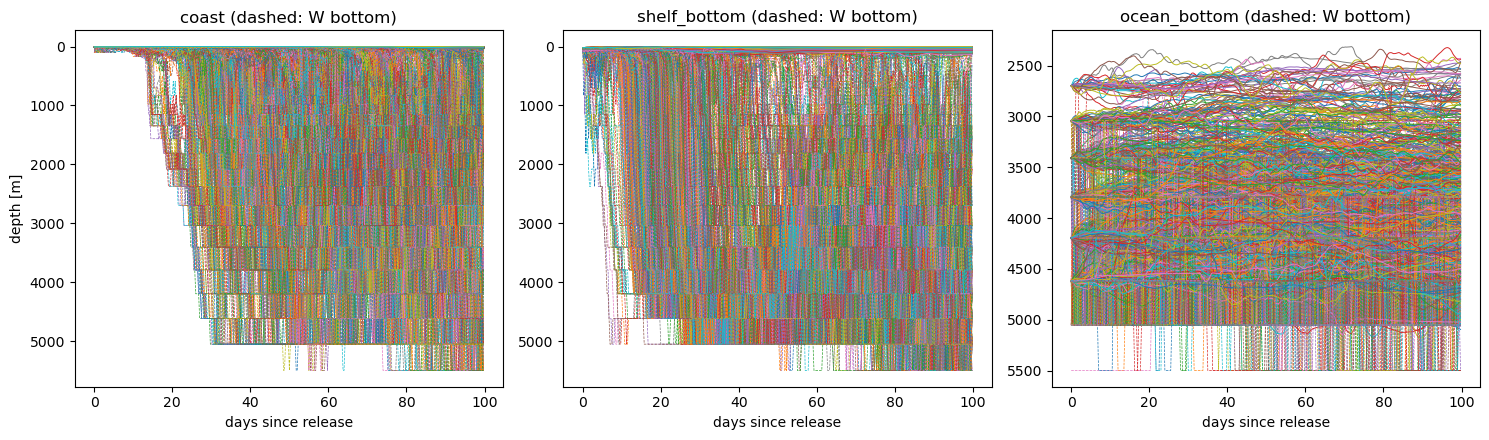

In [21]:
# depth of every particle vs the W bottom under it
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True)
for c, g in enumerate(groups):
    ax = axes[c]
    for p in np.where(grp == c)[0]:
        l, = ax.plot(days, z[p], lw=0.7)
        ax.plot(days, wb[p], lw=0.5, ls='--', color=l.get_color())
    ax.invert_yaxis()
    ax.set_title(f"{g} (dashed: W bottom)")
    ax.set_xlabel('days since release')
axes[0].set_ylabel('depth [m]')
plt.tight_layout()
plt.show()

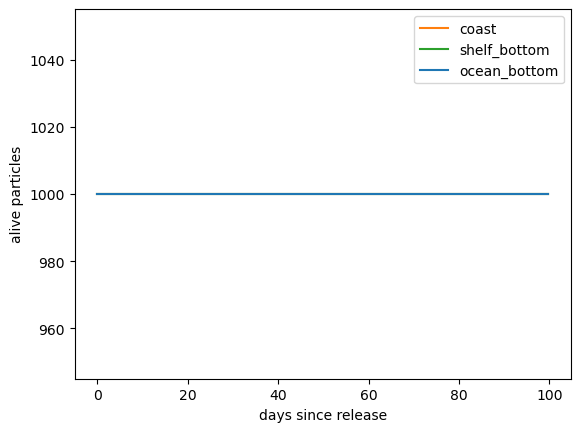

In [22]:
# particles still alive per group
for gi, g in enumerate(groups):
    plt.plot(days, valid[grp == gi].sum(axis=0), color=colors[g], label=g)
plt.ylabel('alive particles'); plt.xlabel('days since release'); plt.legend()
plt.show()